In [ ]:
# БЛОК 1. ПОДКЛЮЧЕНИЕ GOOGLE DRIVE И ПРОВЕРКА НАЛИЧИЯ ФАЙЛА
import os
from google.colab import drive

# 1. Подключение к Google Drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
else:
    print("✓ Google Drive уже подключен")

# 2. Путь к файлу
file_path = '/content/drive/MyDrive/data/banki_responses.json'

# 3. Проверка
if os.path.exists(file_path):
    size_gb = os.path.getsize(file_path) / (1024**3)
    print(f"\n✓ Файл успешно найден!")
    print(f"Путь: {file_path}")
    print(f"Размер: {size_gb:.2f} ГБ")

    # Проверка, сжат ли он (файл)
    with open(file_path, 'rb') as f:
        magic = f.read(3)
    if magic == b'BZh':
        print("Формат: bz2-архив (код распакует его на лету)")
    else:
        print("Формат: обычный текстовый файл / JSON")
else:
    print(f"\n✗ ОШИБКА: Файл не найден по пути {file_path}")
    print("Проверьте, правильно ли указана папка и название файла (регистр имеет значение!).")

✓ Google Drive уже подключен

✓ Файл успешно найден!
Путь: /content/drive/MyDrive/data/banki_responses.json
Размер: 1.45 ГБ
Формат: обычный текстовый файл / JSON


In [ ]:
!pip install pymorphy3 gensim nltk wordcloud -q

import os, json, bz2, random, re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from collections import Counter
from IPython.display import display

import nltk
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords

import pymorphy3
import gensim
from gensim import corpora
from gensim.models import LdaModel

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import TruncatedSVD, LatentDirichletAllocation
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

%matplotlib inline
sns.set_theme(style="whitegrid")
morph = pymorphy3.MorphAnalyzer()
stop_words = set(stopwords.words('russian'))

In [ ]:
# ЗАГРУЗКА ДАННЫХ (file_path из Блока 1)
if 'file_path' not in dir() or not os.path.exists(file_path):
    raise ValueError("Файл не найден! Убедитесь, что Блок 1 выполнен успешно и переменная file_path определена.")

def open_data_file(path):
    with open(path, 'rb') as f:
        magic = f.read(3)
    if magic == b'BZh':
        return bz2.BZ2File(path, 'r')
    else:
        return open(path, 'r', encoding='utf-8')

# Резервуарная выборка 25% для предотвращения переполнения памяти (OOM)
random.seed(42)
FRACTION = 0.25
TARGET = 50000
reservoir = []
n_valid = 0

print("\nНачинаем чтение файла (это может занять пару минут из-за размера)...")
with open_data_file(file_path) as thefile:
    for row in tqdm(thefile, desc="Чтение + выборка 25%"):
        row = row.strip()
        if not row:
            continue
        try:
            resp = json.loads(row)
        except json.JSONDecodeError:
            continue
        if resp.get('rating_not_checked', True):
            continue
        if len(resp.get('text', '').split()) == 0:
            continue

        n_valid += 1
        cap = min(int(n_valid * FRACTION), TARGET)
        if len(reservoir) < cap:
            reservoir.append(resp)
        else:
            j = random.randint(0, n_valid - 1)
            if j < cap:
                reservoir[j] = resp

print(f"\nВсего валидных отзывов в файле: {n_valid}")
print(f"Взято в выборку (≈25%): {len(reservoir)}")
df = pd.DataFrame(reservoir)


Начинаем чтение файла (это может занять пару минут из-за размера)...


Чтение + выборка 25%: 201030it [00:51, 3928.78it/s] 



Всего валидных отзывов в файле: 153499
Взято в выборку (≈25%): 38374



ЧАСТЬ 1. АНАЛИЗ ТЕКСТОВ


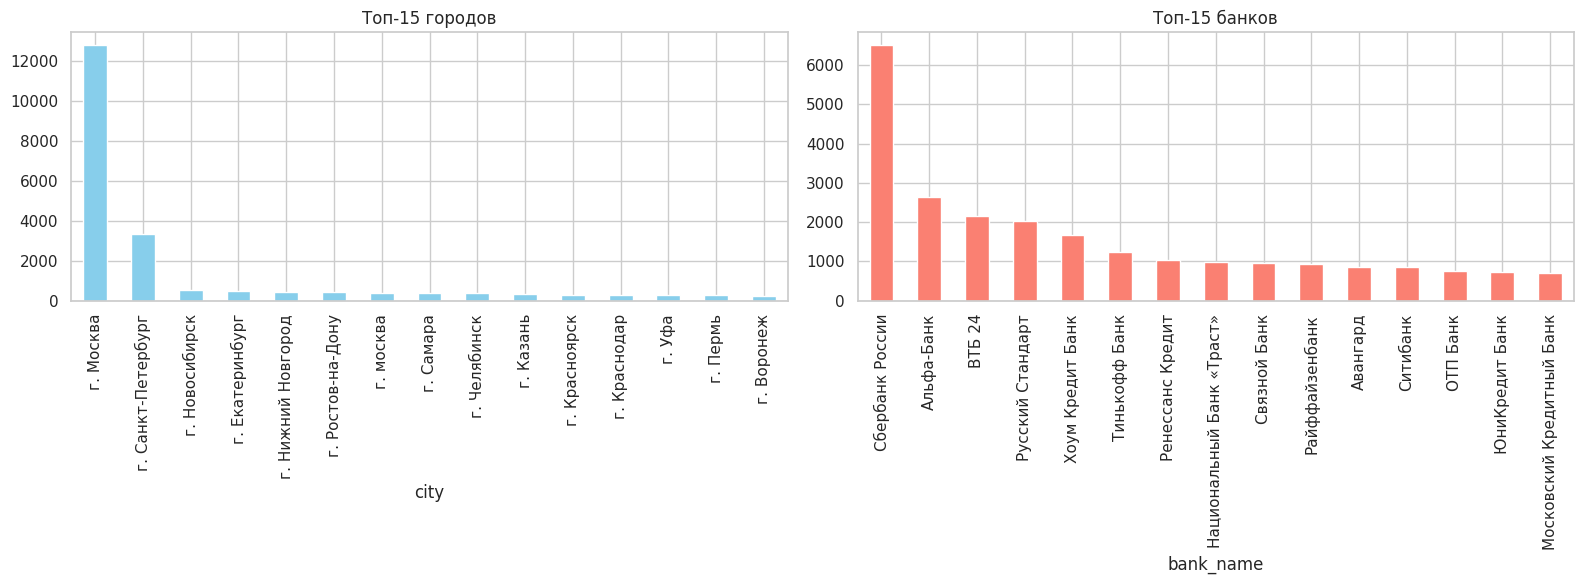

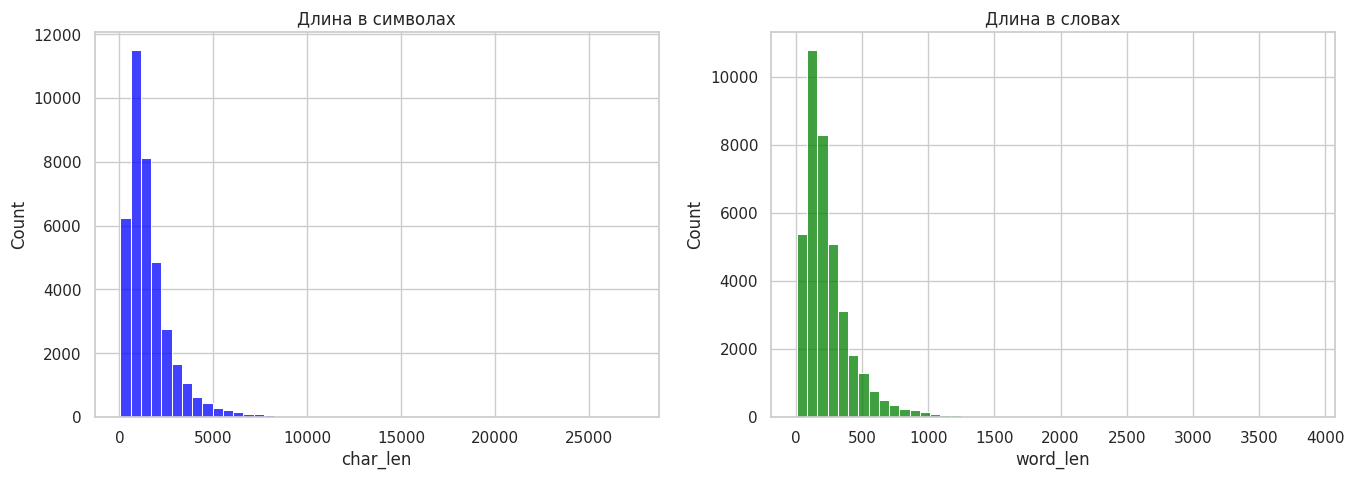

Морфологический анализ: 100%|██████████| 38374/38374 [15:49<00:00, 40.43it/s]



--- Топ-10 слов ---
 [('в', 341788), ('и', 272539), ('не', 218260), ('на', 181135), ('что', 165087), ('я', 147920), ('с', 117200), ('по', 94356), ('мне', 81908), ('банка', 68736)]

--- Топ-10 слов (без стоп-слов) ---
 [('банка', 68736), ('банк', 54177), ('это', 47657), ('деньги', 33743), ('карту', 27771), ('карты', 26326), ('кредит', 20801), ('т', 19248), ('день', 18957), ('очень', 18391)]

--- Топ-10 лемм ---
 [('банк', 167810), ('карта', 87390), ('это', 52016), ('деньга', 46535), ('день', 44142), ('мой', 41661), ('кредит', 39445), ('который', 37951), ('отделение', 37897), ('счёт', 36912)]

--- Топ-10 существительных ---
 [('банк', 167810), ('карта', 87390), ('деньга', 46535), ('день', 44142), ('кредит', 39445), ('отделение', 37897), ('счёт', 36912), ('клиент', 35509), ('сотрудник', 32462), ('сумма', 27937)]


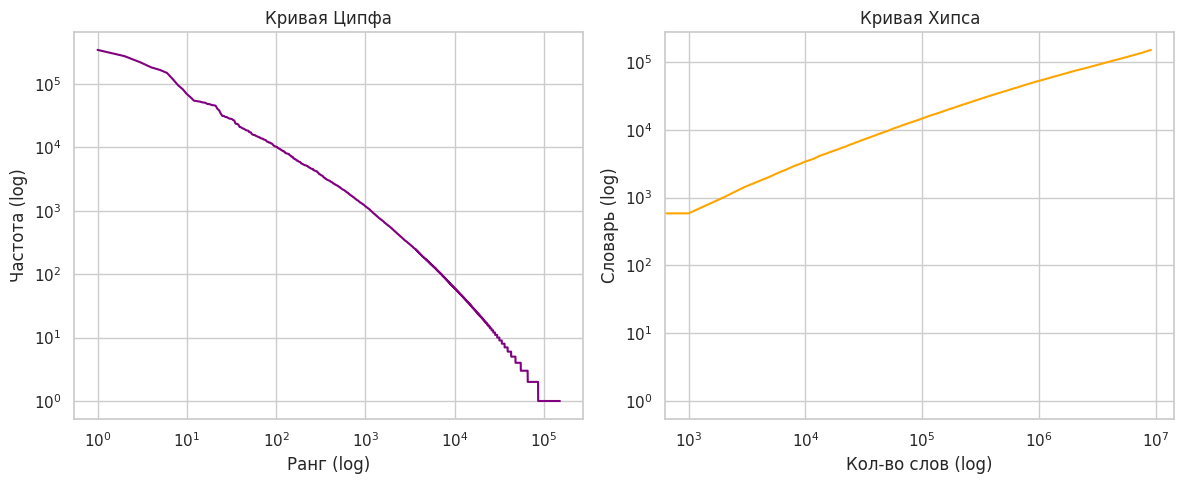


Слово 'сотрудник' встречается: 32462 раз
Слово 'клиент' встречается: 35509 раз
Слово 'мошенничество' встречается: 770 раз
Слово 'доверие' встречается: 537 раз

=== Ключевые слова/биграммы для ОТРИЦАТЕЛЬНЫХ (Оценка 1) ===
  банка: 237.0227
  банк: 199.1214
  деньги: 181.1720
  это: 175.8397
  карту: 149.9043
  карты: 135.5518
  кредит: 126.2781
  заявление: 123.8722
  отделение: 111.4491
  г: 103.5134

=== Ключевые слова/биграммы для ПОЛОЖИТЕЛЬНЫХ (Оценка 5) ===
  банка: 81.8608
  очень: 71.3808
  банк: 70.7510
  это: 61.9406
  кредит: 48.1037
  карту: 48.0436
  деньги: 45.8231
  банке: 42.1699
  вклад: 39.4048
  спасибо: 39.2527


In [ ]:
# ЧАСТЬ 1. АНАЛИЗ ТЕКСТОВ
print("\n" + "="*60 + "\nЧАСТЬ 1. АНАЛИЗ ТЕКСТОВ\n" + "="*60)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
df['city'].value_counts().head(15).plot(kind='bar', ax=axes[0], title='Топ-15 городов', color='skyblue')
df['bank_name'].value_counts().head(15).plot(kind='bar', ax=axes[1], title='Топ-15 банков', color='salmon')
plt.tight_layout()
plt.show()

df['char_len'] = df['text'].apply(len)
df['word_len'] = df['text'].apply(lambda x: len(x.split()))
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(df['char_len'], bins=50, ax=axes[0], color='blue').set_title('Длина в символах')
sns.histplot(df['word_len'], bins=50, ax=axes[1], color='green').set_title('Длина в словах')
plt.show()

def preprocess(text):
    text = re.sub(r'[^а-яА-ЯёЁ]', ' ', text.lower())
    return text.split()

all_words, all_words_no_stop, all_lemmas, all_nouns = [], [], [], []
for text in tqdm(df['text'], desc="Морфологический анализ"):
    words = preprocess(text)
    all_words.extend(words)
    for w in words:
        if w not in stop_words:
            all_words_no_stop.append(w)
            p = morph.parse(w)[0]
            all_lemmas.append(p.normal_form)
            if 'NOUN' in p.tag:
                all_nouns.append(p.normal_form)

print("\n--- Топ-10 слов ---\n", Counter(all_words).most_common(10))
print("\n--- Топ-10 слов (без стоп-слов) ---\n", Counter(all_words_no_stop).most_common(10))
print("\n--- Топ-10 лемм ---\n", Counter(all_lemmas).most_common(10))
print("\n--- Топ-10 существительных ---\n", Counter(all_nouns).most_common(10))

word_counts = sorted(Counter(all_words).values(), reverse=True)
ranks = np.arange(1, len(word_counts) + 1)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.loglog(ranks, word_counts, color='purple')
plt.title('Кривая Ципфа'); plt.xlabel('Ранг (log)'); plt.ylabel('Частота (log)')

vocab = set()
heaps_x, heaps_y = [], []
for i, w in enumerate(all_words):
    vocab.add(w)
    if i % 1000 == 0:
        heaps_x.append(i); heaps_y.append(len(vocab))
plt.subplot(1, 2, 2)
plt.loglog(heaps_x, heaps_y, color='orange')
plt.title('Кривая Хипса'); plt.xlabel('Кол-во слов (log)'); plt.ylabel('Словарь (log)')
plt.tight_layout(); plt.show()

print(f"\nСлово 'сотрудник' встречается: {sum(1 for w in all_lemmas if w == 'сотрудник')} раз")
print(f"Слово 'клиент' встречается: {sum(1 for w in all_lemmas if w == 'клиент')} раз")
print(f"Слово 'мошенничество' встречается: {sum(1 for w in all_lemmas if w == 'мошенничество')} раз")
print(f"Слово 'доверие' встречается: {sum(1 for w in all_lemmas if w == 'доверие')} раз")

df_pos = df[df['rating_grade'] == 5]['text']
df_neg = df[df['rating_grade'] == 1]['text']


def get_top_tfidf(texts, n=10):
    vect = TfidfVectorizer(ngram_range=(1, 2), stop_words=list(stop_words), token_pattern=r'[а-яА-ЯёЁ]+')
    tfidf = vect.fit_transform(texts)

    sum_tfidf = tfidf.sum(axis=0)
    scores = [(word, sum_tfidf[0, idx]) for word, idx in vect.vocabulary_.items()]
    return sorted(scores, key=lambda x: x[1], reverse=True)[:n]

print("\n=== Ключевые слова/биграммы для ОТРИЦАТЕЛЬНЫХ (Оценка 1) ===")
for w, s in get_top_tfidf(df_neg):
    print(f"  {w}: {s:.4f}")
print("\n=== Ключевые слова/биграммы для ПОЛОЖИТЕЛЬНЫХ (Оценка 5) ===")
for w, s in get_top_tfidf(df_pos):
    print(f"  {w}: {s:.4f}")

In [ ]:
# ЧАСТЬ 2. ТЕМАТИЧЕСКОЕ МОДЕЛИРОВАНИЕ

print("\n" + "="*60 + "\nЧАСТЬ 2. ТЕМАТИЧЕСКОЕ МОДЕЛИРОВАНИЕ\n" + "="*60)

import gensim
from gensim import corpora
from gensim.models import LdaModel
from tqdm import tqdm

texts_for_lda = []
for text in tqdm(df['text'], desc="Подготовка к LDA"):
    words = re.sub(r'[^а-яА-ЯёЁ]', ' ', text.lower()).split()
    lemmas = [morph.parse(w)[0].normal_form for w in words if w not in stop_words]
    texts_for_lda.append(lemmas)

dictionary = corpora.Dictionary(texts_for_lda)
dictionary.filter_extremes(no_below=5, no_above=0.5)
corpus = [dictionary.doc2bow(text) for text in texts_for_lda]

lda_models = {}
for num_topics in [5, 10, 15]:
    print(f"\n--- Модель с {num_topics} темами ---")
    lda = LdaModel(corpus=corpus, id2word=dictionary, num_topics=num_topics, random_state=42, passes=5)
    lda_models[num_topics] = lda
    for idx, topic in lda.print_topics(-1, num_words=7):
        print(f"Тема {idx}: {topic}")


ЧАСТЬ 2. ТЕМАТИЧЕСКОЕ МОДЕЛИРОВАНИЕ


Подготовка к LDA: 100%|██████████| 38374/38374 [15:27<00:00, 41.39it/s]



--- Модель с 5 темами ---
Тема 0: 0.056*"карта" + 0.020*"деньга" + 0.015*"банкомат" + 0.015*"счёт" + 0.007*"отделение" + 0.007*"интернет" + 0.006*"проблема"
Тема 1: 0.018*"мой" + 0.015*"счёт" + 0.014*"заявление" + 0.012*"г" + 0.012*"средство" + 0.010*"сотрудник" + 0.009*"который"
Тема 2: 0.052*"кредит" + 0.019*"сумма" + 0.018*"кредитный" + 0.016*"платёж" + 0.013*"договор" + 0.013*"год" + 0.011*"месяц"
Тема 3: 0.013*"звонить" + 0.013*"сказать" + 0.011*"позвонить" + 0.010*"документ" + 0.009*"телефон" + 0.009*"мой" + 0.009*"заявка"
Тема 4: 0.013*"клиент" + 0.012*"вклад" + 0.010*"отделение" + 0.009*"очень" + 0.009*"очередь" + 0.008*"работать" + 0.007*"свой"

--- Модель с 10 темами ---
Тема 0: 0.031*"деньга" + 0.021*"банкомат" + 0.008*"работать" + 0.008*"говорить" + 0.007*"сказать" + 0.007*"карточка" + 0.007*"такой"
Тема 1: 0.021*"телефон" + 0.020*"звонить" + 0.016*"номер" + 0.014*"звонок" + 0.014*"мой" + 0.013*"сотрудник" + 0.013*"ваш"
Тема 2: 0.021*"сумма" + 0.020*"платёж" + 0.019*"счёт"

In [ ]:
print("\n=== ИСПРАВЛЕННЫЙ Поиск тем с упоминанием банков (модель на 10 тем) ===")
lda_10 = lda_models[10]

for bank in ['сбербанк', 'втб', 'альфа', 'тинькофф', 'газпромбанк', 'россельхозбанк']:
    bank_id = dictionary.token2id.get(bank)
    if bank_id is None:
        print(f"Банк '{bank}': слова нет в словаре (слишком редкое).")
        continue

    topic_weights = []
    for topic_id in range(10):
        # ИСПРАВЛЕНИЕ: show_topic возвращает слова (строки), поэтому поиск теперь по названию банка
        terms = dict(lda_10.show_topic(topic_id, topn=1000))
        if terms.get(bank, 0) > 0:
            topic_weights.append((topic_id, terms[bank]))

    if topic_weights:
        topic_weights.sort(key=lambda x: x[1], reverse=True)
        best_topic = topic_weights[0][0]
        weight = topic_weights[0][1]
        print(f"Банк '{bank}' сильнее всего в теме {best_topic} (вес {weight:.4f}): {lda_10.print_topic(best_topic, topn=5)}")
    else:
        print(f"Банк '{bank}' не выделен ни в одну тему.")


=== ИСПРАВЛЕННЫЙ Поиск тем с упоминанием банков (модель на 10 тем) ===
Банк 'сбербанк' сильнее всего в теме 3 (вес 0.0272): 0.037*"счёт" + 0.027*"сбербанк" + 0.023*"перевод" + 0.019*"платёж" + 0.016*"деньга"
Банк 'втб' сильнее всего в теме 8 (вес 0.0028): 0.025*"документ" + 0.018*"заявка" + 0.013*"сказать" + 0.012*"позвонить" + 0.011*"получить"
Банк 'альфа' сильнее всего в теме 5 (вес 0.0024): 0.024*"договор" + 0.014*"мой" + 0.013*"г" + 0.011*"который" + 0.009*"клиент"
Банк 'тинькофф' сильнее всего в теме 7 (вес 0.0003): 0.081*"карта" + 0.010*"интернет" + 0.010*"кредитный" + 0.009*"клиент" + 0.009*"услуга"
Банк 'газпромбанк' сильнее всего в теме 8 (вес 0.0004): 0.025*"документ" + 0.018*"заявка" + 0.013*"сказать" + 0.012*"позвонить" + 0.011*"получить"
Банк 'россельхозбанк' не выделен ни в одну тему.


In [ ]:
# ЧАСТЬ 3. КЛАССИФИКАЦИЯ ТЕКСТОВ

print("\n" + "="*60 + "\nЧАСТЬ 3. КЛАССИФИКАЦИЯ ТЕКСТОВ\n" + "="*60)

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import TruncatedSVD, LatentDirichletAllocation
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from IPython.display import display

N = 1500
neg_pool = df[df['rating_grade'] == 1]
pos_pool = df[df['rating_grade'] == 5]
df_neg_sample = neg_pool.sample(n=min(N, len(neg_pool)), random_state=42)
df_pos_sample = pos_pool.sample(n=min(N, len(pos_pool)), random_state=42)

df_class = pd.concat([df_neg_sample, df_pos_sample]).copy()
df_class['target'] = df_class['rating_grade'].apply(lambda x: 1 if x == 5 else 0)

X = df_class['text']
y = df_class['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Обучающая выборка: {X_train.shape[0]}, Тестовая: {X_test.shape[0]}")

vectorizers = {
    'Униграммы':                 CountVectorizer(ngram_range=(1, 1)),
    'Биграммы':                  CountVectorizer(ngram_range=(2, 2)),
    'Триграммы':                 CountVectorizer(ngram_range=(3, 3)),
    'Символьные n-граммы (3–5)': CountVectorizer(analyzer='char', ngram_range=(3, 5)),
}

baseline_rows = []
print("\n--- Baseline (LogisticRegression) ---")
for name, vect in vectorizers.items():
    pipe = Pipeline([('vect', vect), ('clf', LogisticRegression(max_iter=1000, random_state=42))])
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    print(f"{name}: Accuracy = {acc:.4f} | F1 = {f1:.4f}")
    baseline_rows.append({'Векторизация': name, 'Accuracy': acc, 'F1-score': f1})

print("\nИтог baseline:")
display(pd.DataFrame(baseline_rows))

# ИСПРАВЛЕНИЕ: здесь тоже добавили list(stop_words)
pipe_lsi = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, stop_words=list(stop_words))),
    ('svd',   TruncatedSVD(n_components=100, random_state=42)),
    ('clf',   LogisticRegression(max_iter=1000, random_state=42)),
])
pipe_lsi.fit(X_train, y_train)
preds_lsi = pipe_lsi.predict(X_test)
acc_lsi = accuracy_score(y_test, preds_lsi)
f1_lsi  = f1_score(y_test, preds_lsi)
print(f"\nВариант 1 (TF-IDF + LSI/SVD): Accuracy = {acc_lsi:.4f} | F1 = {f1_lsi:.4f}")

pipe_lda = Pipeline([
    ('vect', CountVectorizer(max_features=5000)),
    ('lda',  LatentDirichletAllocation(n_components=100, random_state=42)),
    ('clf',  LogisticRegression(max_iter=1000, random_state=42)),
])
pipe_lda.fit(X_train, y_train)
preds_lda = pipe_lda.predict(X_test)
acc_lda = accuracy_score(y_test, preds_lda)
f1_lda  = f1_score(y_test, preds_lda)
print(f"Вариант 2 (LDA):               Accuracy = {acc_lda:.4f} | F1 = {f1_lda:.4f}")

print("\nИтог по скрытым темам:")
display(pd.DataFrame([
    {'Метод': 'LSI (SVD)', 'Accuracy': acc_lsi, 'F1-score': f1_lsi},
    {'Метод': 'LDA',       'Accuracy': acc_lda, 'F1-score': f1_lda},
]))


ЧАСТЬ 3. КЛАССИФИКАЦИЯ ТЕКСТОВ
Обучающая выборка: 2400, Тестовая: 600

--- Baseline (LogisticRegression) ---
Униграммы: Accuracy = 0.9133 | F1 = 0.9116
Биграммы: Accuracy = 0.8583 | F1 = 0.8640
Триграммы: Accuracy = 0.7100 | F1 = 0.7655
Символьные n-граммы (3–5): Accuracy = 0.9117 | F1 = 0.9097

Итог baseline:


,Векторизация,Accuracy,F1-score
0,Униграммы,0.913333,0.911565
1,Биграммы,0.858333,0.864000
2,Триграммы,0.710000,0.765499
3,Символьные n-граммы (3–5),0.911667,0.909710



Вариант 1 (TF-IDF + LSI/SVD): Accuracy = 0.9033 | F1 = 0.9020
Вариант 2 (LDA):               Accuracy = 0.8417 | F1 = 0.8325

Итог по скрытым темам:


,Метод,Accuracy,F1-score
0,LSI (SVD),0.903333,0.902027
1,LDA,0.841667,0.832451
